In [1]:
"""
FTT Emulator Plots — Python/Matplotlib equivalents of the R/ggplot2 script.

Usage:
    python plots.py

Expects:
    data/predictions/bases_preds_lhc.csv   (columns include: sample_id, Year, Value,
        emulator, trans_turnover, heat_turnover, lead_solar, lead_onshore,
        cr_wind, cr_solar, trans_rebound, heat_rebound, prediction)
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from pathlib import Path
import sys
import os

# Set root directory
__file__ = os.getcwd()  # Set __file__ to current working directory for interactive environments
root_dir = os.path.dirname(os.path.abspath(__file__))
sys.path.append(root_dir)
os.chdir(root_dir)
print(f"Current working directory: {os.getcwd()}")

Current working directory: c:\Users\ib400\Github\rebound_emulation\Emulation


In [2]:
# ── Paths ──────────────────────────────────────────────────────────────────────
DATA_PATH   = Path("data/predictions")
FIGURES_DIR = Path("data/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

PREDS_FILE  = DATA_PATH / "bases_preds_lhc.csv"

# ── Colour palette (matching R script intent) ──────────────────────────────────
COLOURS = {
    "energy_demand_no": "#d73027",   # no rebound  → warm red
    "energy_demand_rb": "#4575b4",   # rebound     → blue
    "no rebound":       "#d73027",
    "rebound":          "#4575b4",
}

# ── Shared theme helper ────────────────────────────────────────────────────────
def apply_theme(ax, xlabel="", ylabel="", fontsize=9):
    """Apply the clean, minimal style used throughout the reference script."""
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(labelsize=fontsize - 1)
    ax.yaxis.grid(True, linestyle="--", linewidth=0.4, alpha=0.4)
    ax.set_axisbelow(True)
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=fontsize, fontweight="bold")
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=fontsize, fontweight="bold")


# ── Policy-factor labelling ────────────────────────────────────────────────────
def add_policy_factors(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["Value"] = df["Value"] / 1000  # TJ → PJ (same as /1000 in R)

    # Binary turnover
    conditions = [
        (df["trans_turnover"] == 0) & (df["heat_turnover"] == 0),
        (df["trans_turnover"] == 1) & (df["heat_turnover"] == 1),
    ]
    df["turn_level_bi"] = np.select(conditions,
                                     ["low turnover", "high turnover"],
                                     default=None)

    # Continuous-threshold turnover
    df["turn_level"] = np.where(
        (df["trans_turnover"] < 0.5) & (df["heat_turnover"] < 0.5),
        "low turnover",
        np.where(
            (df["trans_turnover"] >= 0.5) & (df["heat_turnover"] >= 0.5),
            "high turnover", None
        )
    )

    # Rebound level
    df["reb_level"] = np.where(
        (df["trans_rebound"] < 0.5) & (df["heat_rebound"] < 0.5),
        "low rebound",
        np.where(
            (df["trans_rebound"] >= 0.5) & (df["heat_rebound"] >= 0.5),
            "high rebound", None
        )
    )

    # # Rebound active flag
    # df["reb_active"] = np.where(df["reb_switch"] == 0, "no rebound", "rebound")

    # Tech leads
    df["leads"] = np.where(
        (df["lead_solar"] < 0.5) & (df["lead_onshore"] < 0.5),
        "Short tech lead",
        np.where(
            (df["lead_solar"] >= 0.5) & (df["lead_onshore"] >= 0.5),
            "Long tech lead", None
        )
    )

    # Cannibalisation rate
    df["cr_total"] = np.where(
        (df["cr_wind"] < 0.5) & (df["cr_solar"] < 0.5),
        "Low Cannibalisation",
        np.where(
            (df["cr_solar"] >= 0.5) & (df["cr_wind"] >= 0.5),
            "High Cannibalisation", None
        )
    )

    # Power transition composite
    df["power_transition"] = np.where(
        (df["cr_total"] == "High Cannibalisation") & (df["leads"] == "Long tech lead"),
        "slow transition",
        np.where(
            (df["cr_total"] == "Low Cannibalisation") & (df["leads"] == "Short tech lead"),
            "fast transition", None
        )
    )

    return df


In [3]:

# ══════════════════════════════════════════════════════════════════════════════
# PLOT 2 — Emissions density: Power-system scenarios (leads × cr_total)
# ══════════════════════════════════════════════════════════════════════════════
def plot_emissions_power_scenarios(df: pd.DataFrame):
    """
    KDE density of cumulative emissions faceted by leads (rows) × cr_total (cols),
    filled by reb_active. Dashed vlines mark group means.
    """
    from scipy.stats import gaussian_kde

    row_vals = ["Short tech lead", "Long tech lead"]
    col_vals = ["Low Cannibalisation", "High Cannibalisation"]

    sub = df.dropna(subset=["leads", "cr_total"]).copy()

    summary = (sub
               .groupby(["emulator", "leads", "cr_total"])["Value"]
               .mean()
               .reset_index()
               .rename(columns={"Value": "mean_pred"}))

    fig, axes = plt.subplots(len(row_vals), len(col_vals),
                             figsize=(9, 6), sharey=False, sharex=False)
    fig.subplots_adjust(hspace=0.45, wspace=0.35)

    rebound_groups = {
        "no rebound": (sub["emulator"] == 0,  COLOURS["no rebound"]),
        "rebound":    (sub["emulator"] == 1,  COLOURS["rebound"]),
    }

    for ri, row_v in enumerate(row_vals):
        for ci, col_v in enumerate(col_vals):
            ax = axes[ri][ci]
            cell = sub[(sub["leads"] == row_v) & (sub["cr_total"] == col_v)]

            for label, (mask, colour) in rebound_groups.items():
                data = cell.loc[mask, "Value"].dropna()
                if len(data) < 10:
                    continue
                kde  = gaussian_kde(data, bw_method=0.3)
                xs   = np.linspace(data.min(), data.max(), 300)
                ax.fill_between(xs, kde(xs), alpha=0.45, color=colour, label=label)
                ax.plot(xs, kde(xs), color=colour, lw=1)

            # Vlines for means
            vline_data = summary[
                (summary["leads"] == row_v) & (summary["cr_total"] == col_v)
            ]
            for _, vrow in vline_data.iterrows():
                reb_col = COLOURS["rebound"] if vrow["emulator"] == 1 else COLOURS["no rebound"]
                ax.axvline(vrow["mean_pred"], color=reb_col,
                           linestyle="--", linewidth=0.8)

            apply_theme(ax, fontsize=8)
            ax.tick_params(axis="x", rotation=45)
            ax.set_xlabel(r"Emissions (GtCO$_2$ cumulative)", fontsize=7)
            ax.set_ylabel("Density", fontsize=7)

            # Facet labels
            if ri == 0:
                ax.set_title(col_v, fontsize=8, fontweight="bold", pad=4)
            if ci == 0:
                ax.set_ylabel(f"{row_v}\nDensity", fontsize=7)

    # Shared legend
    legend_patches = [
        Line2D([0], [0], color=COLOURS["no rebound"], lw=8, alpha=0.5,
               label="No rebound"),
        Line2D([0], [0], color=COLOURS["rebound"], lw=8, alpha=0.5,
               label="Rebound"),
    ]
    fig.legend(handles=legend_patches,
               loc="lower center", ncol=2, fontsize=8,
               frameon=False, bbox_to_anchor=(0.5, -0.04))
    fig.suptitle("Emissions under Power System Scenarios", fontsize=11,
                 fontweight="bold", y=1.01)
    plt.tight_layout()
    out = FIGURES_DIR / "emissions_power_scenarios.png"
    fig.savefig(out, dpi=150, bbox_inches="tight")
    print(f"Saved → {out}")
    plt.show()

In [12]:
plt.style.use("default")

print("Loading data …")
df = pd.read_csv(PREDS_FILE)
df = add_policy_factors(df)

row_vals = ["Short tech lead", "Long tech lead"]
col_vals = ["Low Cannibalisation", "High Cannibalisation"]

sub = df.dropna(subset=["leads", "cr_total"]).copy()

summary = (sub
            .groupby(["emulator", "leads", "cr_total"])["Value"]
            .mean()
            .reset_index()
            .rename(columns={"Value": "mean_pred"}))

Loading data …


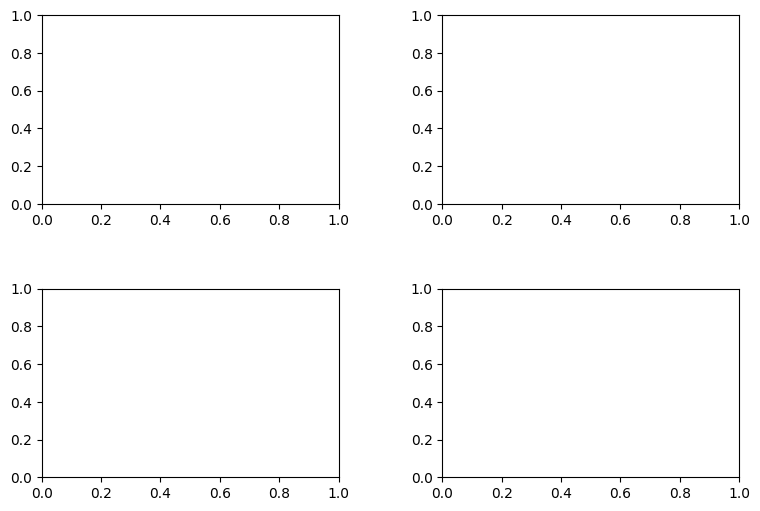

In [13]:
fig, axes = plt.subplots(len(row_vals), len(col_vals),
                        figsize=(9, 6), sharey=False, sharex=False)
fig.subplots_adjust(hspace=0.45, wspace=0.35)

rebound_groups = {
"no rebound": (sub["emulator"] == 0,  COLOURS["no rebound"]),
"rebound":    (sub["emulator"] == 1,  COLOURS["rebound"]),
}
plt.show()

Saved → data\figures\emissions_power_scenarios.png


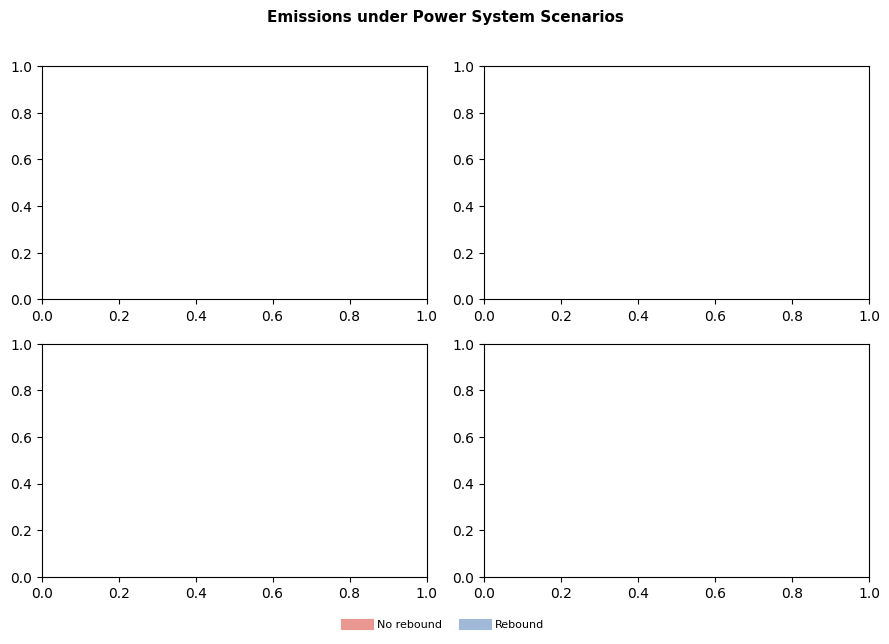

In [16]:
fig, axes = plt.subplots(len(row_vals), len(col_vals),
                        figsize=(9, 6), sharey=False, sharex=False)
fig.subplots_adjust(hspace=0.45, wspace=0.35)

rebound_groups = {
"no rebound": (sub["emulator"] == 0,  COLOURS["no rebound"]),
"rebound":    (sub["emulator"] == 1,  COLOURS["rebound"]),
}

# Shared legend
legend_patches = [
       Line2D([0], [0], color=COLOURS["no rebound"], lw=8, alpha=0.5,
              label="No rebound"),
       Line2D([0], [0], color=COLOURS["rebound"], lw=8, alpha=0.5,
              label="Rebound"),
]
fig.legend(handles=legend_patches,
              loc="lower center", ncol=2, fontsize=8,
              frameon=False, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Emissions under Power System Scenarios", fontsize=11,
              fontweight="bold", y=1.01)
plt.tight_layout()
out = FIGURES_DIR / "emissions_power_scenarios.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
print(f"Saved → {out}")
plt.show()

Saved → data\figures\emissions_power_scenarios.png


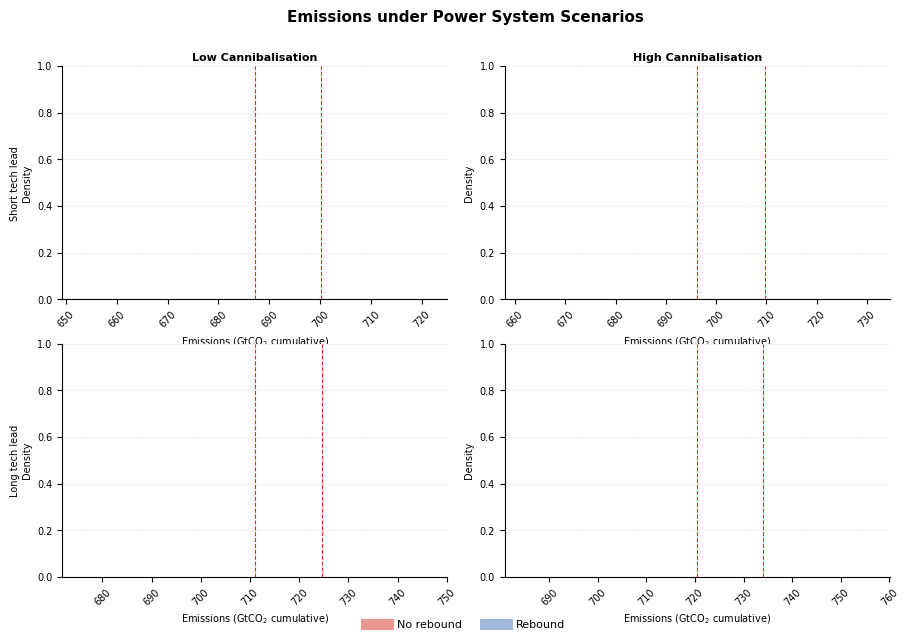

In [17]:
fig, axes = plt.subplots(len(row_vals), len(col_vals),
                        figsize=(9, 6), sharey=False, sharex=False)
fig.subplots_adjust(hspace=0.45, wspace=0.35)

rebound_groups = {
"no rebound": (sub["emulator"] == 0,  COLOURS["no rebound"]),
"rebound":    (sub["emulator"] == 1,  COLOURS["rebound"]),
}

# Shared legend
legend_patches = [
       Line2D([0], [0], color=COLOURS["no rebound"], lw=8, alpha=0.5,
              label="No rebound"),
       Line2D([0], [0], color=COLOURS["rebound"], lw=8, alpha=0.5,
              label="Rebound"),
]
fig.legend(handles=legend_patches,
              loc="lower center", ncol=2, fontsize=8,
              frameon=False, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Emissions under Power System Scenarios", fontsize=11,
              fontweight="bold", y=1.01)
plt.tight_layout()
out = FIGURES_DIR / "emissions_power_scenarios.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
print(f"Saved → {out}")

for ri, row_v in enumerate(row_vals):
    for ci, col_v in enumerate(col_vals):
        ax = axes[ri][ci]
        cell = sub[(sub["leads"] == row_v) & (sub["cr_total"] == col_v)]

        for label, (mask, colour) in rebound_groups.items():
            data = cell.loc[mask, "Value"].dropna()
            if len(data) < 10:
                continue
            kde  = gaussian_kde(data, bw_method=0.3)
            xs   = np.linspace(data.min(), data.max(), 300)
            ax.fill_between(xs, kde(xs), alpha=0.45, color=colour, label=label)
            ax.plot(xs, kde(xs), color=colour, lw=1)

        # Vlines for means
        vline_data = summary[
            (summary["leads"] == row_v) & (summary["cr_total"] == col_v)
        ]
        for _, vrow in vline_data.iterrows():
            reb_col = COLOURS["rebound"] if vrow["emulator"] == 1 else COLOURS["no rebound"]
            ax.axvline(vrow["mean_pred"], color=reb_col,
                        linestyle="--", linewidth=0.8)

        apply_theme(ax, fontsize=8)
        ax.tick_params(axis="x", rotation=45)
        ax.set_xlabel(r"Emissions (GtCO$_2$ cumulative)", fontsize=7)
        ax.set_ylabel("Density", fontsize=7)

        # Facet labels
        if ri == 0:
            ax.set_title(col_v, fontsize=8, fontweight="bold", pad=4)
        if ci == 0:
            ax.set_ylabel(f"{row_v}\nDensity", fontsize=7)

plt.show()

In [4]:
# ── Main ───────────────────────────────────────────────────────────────────────
def main():
    plt.style.use("default")

    print("Loading data …")
    df = pd.read_csv(PREDS_FILE)
    df = add_policy_factors(df)

 

    # ------------------------------------------------------------------
    # For plots 2 & 3 the R script uses df (a pre-aggregated global
    # emissions frame with a `Value` column).  If your CSV already
    # has `Value`, the same df can be used directly.
    # ------------------------------------------------------------------


    # Plot 2: Emissions density by power-system scenarios
    plot_emissions_power_scenarios(df)


In [6]:
os.getcwd()


'c:\\Users\\ib400\\Github\\rebound_emulation\\Emulation'

Loading data …
Saved → data\figures\emissions_power_scenarios.png


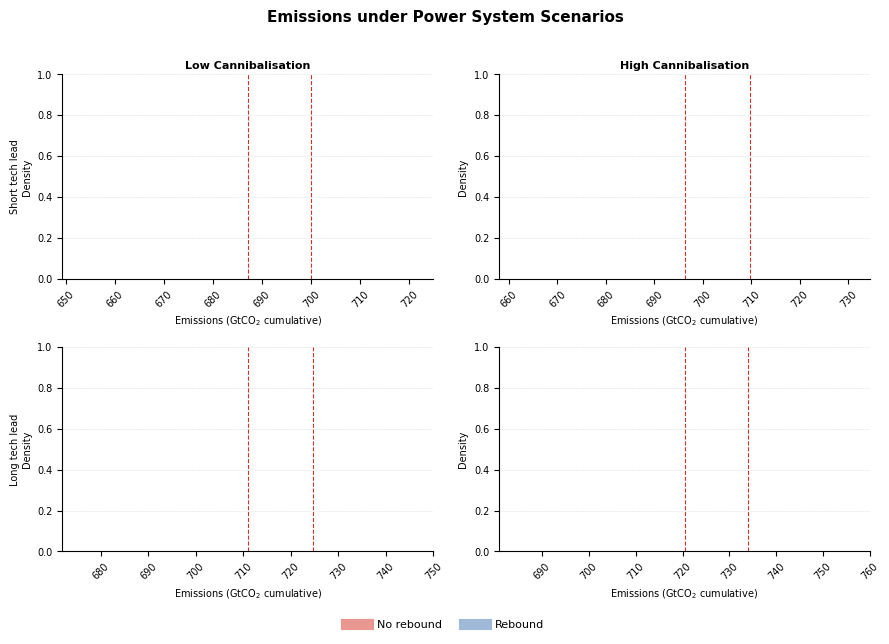

In [8]:
main()